<a href="https://colab.research.google.com/github/dzikrilazizhakim/Semester-5/blob/main/DATA_SCIENCE_SESI_6_DATA_PROCESSING_DZIKRIL_AZIZ_HAKIM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

RAW_PATH    = "nasabah_raw.csv"
EXT_PATH    = "data_kredit_eksternal.csv"
OUTPUT_PATH = "clean_nasabah_final.csv"

# Di Google Colab: minta upload file jika belum ada
if "google.colab" in sys.modules and not (os.path.exists(RAW_PATH) and os.path.exists(EXT_PATH)):
    from google.colab import files
    print("Silakan upload nasabah_raw.csv dan data_kredit_eksternal.csv")
    files.upload()

print("File nasabah_raw.csv ada          :", os.path.exists(RAW_PATH))
print("File data_kredit_eksternal.csv ada:", os.path.exists(EXT_PATH))

Silakan upload nasabah_raw.csv dan data_kredit_eksternal.csv


Saving data_kredit_eksternal.csv to data_kredit_eksternal.csv
Saving nasabah_raw.csv to nasabah_raw.csv
File nasabah_raw.csv ada          : True
File data_kredit_eksternal.csv ada: True


In [ ]:
df_raw = pd.read_csv(RAW_PATH)
df_ext = pd.read_csv(EXT_PATH)

print("Dimensi nasabah_raw.csv          :", df_raw.shape)
print("Dimensi data_kredit_eksternal.csv:", df_ext.shape)
print()
df_raw.info()
display(df_raw.head())

Dimensi nasabah_raw.csv          : (1045, 9)
Dimensi data_kredit_eksternal.csv: (850, 3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
0,CUST-1001,58.00,"10,118,000.00",542.00,13.00,Menikah,Magister,0,"121,416,000.00"
1,CUST-1002,48.00,"10,514,000.00",331.00,20.00,Menikah,Sarjana,0,"126,168,000.00"
2,CUST-1003,34.00,"13,257,000.00",690.00,22.00,Menikah,Magister,0,"159,084,000.00"
3,CUST-1004,27.00,"10,832,000.00",576.00,7.00,Menikah,Sarjana,0,"129,984,000.00"
4,CUST-1005,-5.00,"8,295,000.00",831.00,15.00,Single,SMA,0,"99,540,000.00"


In [ ]:
def cek_dan_hapus_duplikat(df):
    """Hitung duplikat penuh, tampilkan sampel, lalu hapus (simpan kemunculan pertama)."""
    n_dup = df.duplicated().sum()
    print(f"Jumlah baris duplikat penuh: {n_dup}")
    sampel = df[df.duplicated(keep=False)].sort_values("ID_Pelanggan")
    print("\nSampel baris yang terduplikasi (kedua salinan ditampilkan berdampingan):")
    display(sampel.head(10))
    df_bersih = df.drop_duplicates(keep="first").reset_index(drop=True)
    return df_bersih, n_dup

df, n_dup = cek_dan_hapus_duplikat(df_raw)
print("\nID_Pelanggan duplikat setelah dihapus:", df["ID_Pelanggan"].duplicated().sum())

Jumlah baris duplikat penuh: 45

Sampel baris yang terduplikasi (kedua salinan ditampilkan berdampingan):


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.00,"14,765,000.00",461.00,3.00,Single,SMA,0,"177,180,000.00"
1039,CUST-1060,53.00,"14,765,000.00",461.00,3.00,Single,SMA,0,"177,180,000.00"
76,CUST-1077,34.00,"6,920,000.00",510.00,22.00,Single,SMA,1,"83,040,000.00"
1011,CUST-1077,34.00,"6,920,000.00",510.00,22.00,Single,SMA,1,"83,040,000.00"
96,CUST-1097,27.00,"12,499,000.00",578.00,4.00,Single,Sarjana,0,"149,988,000.00"
1041,CUST-1097,27.00,"12,499,000.00",578.00,4.00,Single,Sarjana,0,"149,988,000.00"
101,CUST-1102,43.00,"7,972,000.00",365.00,6.00,Single,Magister,1,"95,664,000.00"
1026,CUST-1102,43.00,"7,972,000.00",365.00,6.00,Single,Magister,1,"95,664,000.00"
1009,CUST-1137,-5.00,NaN,580.00,11.00,Cerai,Sarjana,1,NaN
136,CUST-1137,-5.00,NaN,580.00,11.00,Cerai,Sarjana,1,NaN



ID_Pelanggan duplikat setelah dihapus: 0


In [ ]:
print(f"Baris sebelum : {len(df_raw)}")
print(f"Duplikat      : {n_dup}")
print(f"Baris sesudah : {len(df)}   ->  dimensi {df.shape}")

Baris sebelum : 1045
Duplikat      : 45
Baris sesudah : 1000   ->  dimensi (1000, 9)


In [ ]:
print("Nilai unik SEBELUM dibersihkan:")
print(df["Status_Pernikahan"].map(repr).value_counts())

def standarkan_teks(seri):
    """Hapus spasi di awal/akhir lalu seragamkan kapitalisasi (Title Case)."""
    return seri.str.strip().str.title()

df["Status_Pernikahan"] = standarkan_teks(df["Status_Pernikahan"])

print("\nNilai unik SESUDAH dibersihkan:")
print(df["Status_Pernikahan"].value_counts())

Nilai unik SEBELUM dibersihkan:
Status_Pernikahan
'Menikah'      509
'Single'       342
'Cerai'         82
'single'        37
' MENIKAH '     30
Name: count, dtype: int64

Nilai unik SESUDAH dibersihkan:
Status_Pernikahan
Menikah    539
Single     379
Cerai       82
Name: count, dtype: int64


In [ ]:
USIA_MIN, USIA_MAX = 17, 100

invalid = ~df["Usia"].between(USIA_MIN, USIA_MAX)
print("Statistik Usia sebelum validasi:")
print(df["Usia"].describe())
print(f"\nJumlah usia di luar {USIA_MIN}-{USIA_MAX}: {invalid.sum()}")
print("Nilai yang melanggar:")
print(df.loc[invalid, "Usia"].value_counts())

df["Usia"] = df["Usia"].where(~invalid, np.nan)   # nilai tidak wajar -> NaN
print(f"\nMissing value Usia setelah validasi: {df['Usia'].isna().sum()}")

Statistik Usia sebelum validasi:
count   1,000.00
mean       42.02
std        33.80
min        -5.00
25%        29.00
50%        41.00
75%        51.00
max       350.00
Name: Usia, dtype: float64

Jumlah usia di luar 17-100: 35
Nilai yang melanggar:
Usia
-5.00     25
350.00    10
Name: count, dtype: int64

Missing value Usia setelah validasi: 35


Kolom tersisa: ['ID_Pelanggan', 'Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Status_Pernikahan', 'Tingkat_Pendidikan', 'Status_Default']


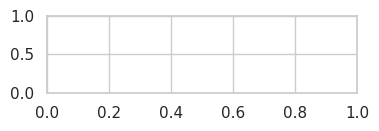

In [ ]:
df = df.drop(columns=["Pendapatan_Tahunan_Est"])
print("Kolom tersisa:", list(df.columns))

In [ ]:
rasio = (df["Pendapatan_Tahunan_Est"] / df["Pendapatan_Bulanan"]).dropna()
print("Rasio Pendapatan_Tahunan_Est / Pendapatan_Bulanan:")
print(rasio.describe())

Rasio Pendapatan_Tahunan_Est / Pendapatan_Bulanan:
count   940.00
mean     12.00
std       0.00
min      12.00
25%      12.00
50%      12.00
75%      12.00
max      12.00
dtype: float64


In [ ]:
def gabung_data(df_utama, df_eksternal, kunci="ID_Pelanggan"):
    """Left join agar seluruh nasabah utama tetap terjaga."""
    return df_utama.merge(df_eksternal, on=kunci, how="left", validate="one_to_one")

n_sebelum = len(df)
df_merged = gabung_data(df, df_ext)

print("Dimensi data nasabah utama   :", df.shape)
print("Dimensi data eksternal       :", df_ext.shape)
print("Dimensi SETELAH penggabungan :", df_merged.shape)
print("Jumlah baris nasabah tetap terjaga:", len(df_merged) == n_sebelum)
print("Nasabah tanpa pasangan di data eksternal:",
      (~df["ID_Pelanggan"].isin(df_ext["ID_Pelanggan"])).sum())
display(df_merged.head())

Dimensi data nasabah utama   : (1000, 8)
Dimensi data eksternal       : (850, 3)
Dimensi SETELAH penggabungan : (1000, 10)
Jumlah baris nasabah tetap terjaga: True
Nasabah tanpa pasangan di data eksternal: 150


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit
0,CUST-1001,58.00,"10,118,000.00",542.00,13.00,Menikah,Magister,0,Tidak,5.00
1,CUST-1002,48.00,"10,514,000.00",331.00,20.00,Menikah,Sarjana,0,Tidak,3.00
2,CUST-1003,34.00,"13,257,000.00",690.00,22.00,Menikah,Magister,0,Tidak,5.00
3,CUST-1004,27.00,"10,832,000.00",576.00,7.00,Menikah,Sarjana,0,Ya,6.00
4,CUST-1005,NaN,"8,295,000.00",831.00,15.00,Single,SMA,0,Ya,4.00


In [ ]:
def laporan_missing(df):
    miss = pd.DataFrame({
        "Jumlah_Missing": df.isna().sum(),
        "Persentase_(%)": df.isna().mean() * 100,
    })
    return miss.sort_values("Persentase_(%)", ascending=False)

display(laporan_missing(df_merged))

,Jumlah_Missing,Persentase_(%)
Jumlah_Kartu_Kredit,150,15.00
Pernah_Gagal_Bayar_Lain,150,15.00
Pendapatan_Bulanan,60,6.00
Lama_Bekerja_Thn,40,4.00
Tingkat_Pendidikan,35,3.50
Usia,35,3.50
ID_Pelanggan,0,0.00
Skor_Kredit,0,0.00
Status_Pernikahan,0,0.00
Status_Default,0,0.00


In [ ]:
def imputasi(df):
    df = df.copy()
    # (1) Numerik kontinu -> median
    for kol in ["Usia", "Pendapatan_Bulanan", "Lama_Bekerja_Thn"]:
        med = df[kol].median()
        df[kol] = df[kol].fillna(med)
        print(f"{kol:<20}: diisi median = {med:,.0f}")
    # (2) Diskrit -> 0 (asumsi tidak punya kartu kredit)
    df["Jumlah_Kartu_Kredit"] = df["Jumlah_Kartu_Kredit"].fillna(0).astype(int)
    print(f"{'Jumlah_Kartu_Kredit':<20}: diisi 0")
    # (3) Kategorikal -> modus
    for kol in ["Tingkat_Pendidikan", "Pernah_Gagal_Bayar_Lain"]:
        modus = df[kol].mode()[0]
        df[kol] = df[kol].fillna(modus)
        print(f"{kol:<24}: diisi modus = '{modus}'")
    return df

df_imp = imputasi(df_merged)

Usia                : diisi median = 41
Pendapatan_Bulanan  : diisi median = 12,132,000
Lama_Bekerja_Thn    : diisi median = 13
Jumlah_Kartu_Kredit : diisi 0
Tingkat_Pendidikan      : diisi modus = 'Sarjana'
Pernah_Gagal_Bayar_Lain : diisi modus = 'Tidak'


In [ ]:
sisa = df_imp.isna().sum()
display(sisa.to_frame("Missing_Tersisa"))
assert df_imp.isna().sum().sum() == 0, "Masih ada missing value!"
print("✅ Tidak ada missing value yang tersisa. Total =", int(df_imp.isna().sum().sum()))

,Missing_Tersisa
ID_Pelanggan,0
Usia,0
Pendapatan_Bulanan,0
Skor_Kredit,0
Lama_Bekerja_Thn,0
Status_Pernikahan,0
Tingkat_Pendidikan,0
Status_Default,0
Pernah_Gagal_Bayar_Lain,0
Jumlah_Kartu_Kredit,0


✅ Tidak ada missing value yang tersisa. Total = 0


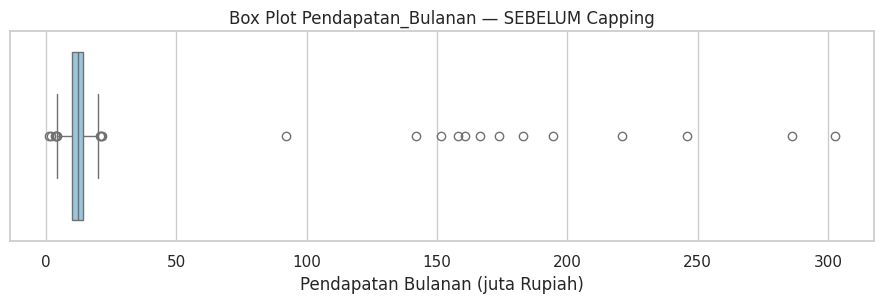

count         1,000.00
mean     14,342,849.57
std      21,464,053.75
min       1,295,000.00
25%      10,192,000.00
50%      12,132,000.00
75%      14,100,250.00
max     302,603,099.92
Name: Pendapatan_Bulanan, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.boxplot(x=df_imp["Pendapatan_Bulanan"] / 1e6, color="#8ecae6", ax=ax)
ax.set_title("Box Plot Pendapatan_Bulanan — SEBELUM Capping")
ax.set_xlabel("Pendapatan Bulanan (juta Rupiah)")
plt.tight_layout()
plt.show()

print(df_imp["Pendapatan_Bulanan"].describe())

In [ ]:
def hitung_batas_iqr(seri, k=1.5):
    q1, q3 = seri.quantile(0.25), seri.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - k * iqr, q3 + k * iqr

q1, q3, iqr, batas_bawah, batas_atas = hitung_batas_iqr(df_imp["Pendapatan_Bulanan"])
print(f"Q1          = {q1:,.0f}")
print(f"Q3          = {q3:,.0f}")
print(f"IQR         = {iqr:,.0f}")
print(f"Batas Bawah = Q1 - 1.5 x IQR = {batas_bawah:,.0f}")
print(f"Batas Atas  = Q3 + 1.5 x IQR = {batas_atas:,.0f}")

mask_out = (df_imp["Pendapatan_Bulanan"] < batas_bawah) | (df_imp["Pendapatan_Bulanan"] > batas_atas)
print(f"\nJumlah outlier       : {mask_out.sum()} ({mask_out.mean()*100:.1f}% data)")
print(f"  - di bawah batas   : {(df_imp['Pendapatan_Bulanan'] < batas_bawah).sum()}")
print(f"  - di atas batas    : {(df_imp['Pendapatan_Bulanan'] > batas_atas).sum()}")
print(f"Default rate baris outlier : {df_imp.loc[mask_out, 'Status_Default'].mean()*100:.1f}%  "
      f"({df_imp.loc[mask_out, 'Status_Default'].sum()} nasabah default)")
print(f"Default rate seluruh data  : {df_imp['Status_Default'].mean()*100:.1f}%")

Q1          = 10,192,000
Q3          = 14,100,250
IQR         = 3,908,250
Batas Bawah = Q1 - 1.5 x IQR = 4,329,625
Batas Atas  = Q3 + 1.5 x IQR = 19,962,625

Jumlah outlier       : 22 (2.2% data)
  - di bawah batas   : 6
  - di atas batas    : 16
Default rate baris outlier : 22.7%  (5 nasabah default)
Default rate seluruh data  : 20.2%


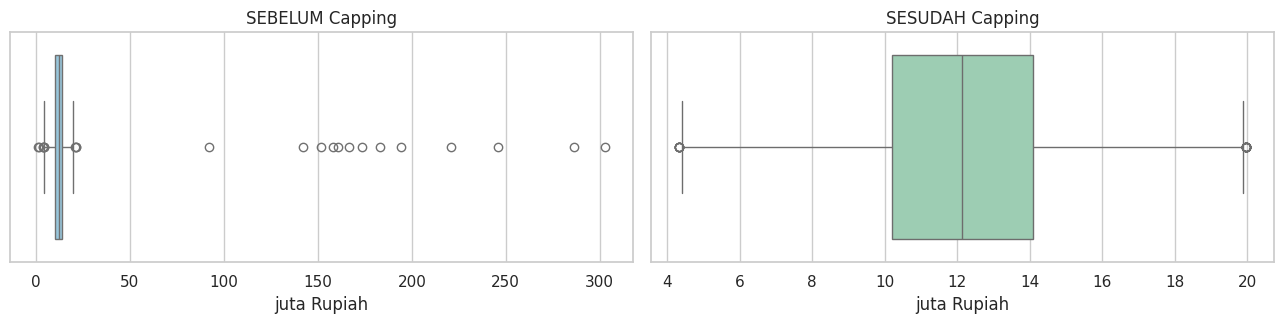

Jumlah baris sebelum capping: 1000 | sesudah: 1000
Max sebelum: 302,603,100  ->  sesudah: 19,962,625
Min sebelum: 1,295,000  ->  sesudah: 4,329,625


In [ ]:
df_cap = df_imp.copy()
df_cap["Pendapatan_Bulanan"] = df_cap["Pendapatan_Bulanan"].clip(lower=batas_bawah, upper=batas_atas)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharex=False)
sns.boxplot(x=df_imp["Pendapatan_Bulanan"] / 1e6, color="#8ecae6", ax=axes[0])
axes[0].set_title("SEBELUM Capping"); axes[0].set_xlabel("juta Rupiah")
sns.boxplot(x=df_cap["Pendapatan_Bulanan"] / 1e6, color="#95d5b2", ax=axes[1])
axes[1].set_title("SESUDAH Capping"); axes[1].set_xlabel("juta Rupiah")
plt.tight_layout()
plt.show()

print("Jumlah baris sebelum capping:", len(df_imp), "| sesudah:", len(df_cap))
print(f"Max sebelum: {df_imp['Pendapatan_Bulanan'].max():,.0f}  ->  sesudah: {df_cap['Pendapatan_Bulanan'].max():,.0f}")
print(f"Min sebelum: {df_imp['Pendapatan_Bulanan'].min():,.0f}  ->  sesudah: {df_cap['Pendapatan_Bulanan'].min():,.0f}")

In [ ]:
df_enc = df_cap.copy()

peta_pendidikan = {"SMA": 1, "Sarjana": 2, "Magister": 3}
df_enc["Pendidikan_Ordinal"] = df_enc["Tingkat_Pendidikan"].map(peta_pendidikan)

display(df_enc[["Tingkat_Pendidikan", "Pendidikan_Ordinal"]].value_counts().to_frame("Jumlah"))

,,Jumlah
Tingkat_Pendidikan,Pendidikan_Ordinal,
Sarjana,2,509
SMA,1,297
Magister,3,194


In [ ]:
df_enc["Gagal_Bayar_Lain_Biner"] = df_enc["Pernah_Gagal_Bayar_Lain"].map({"Tidak": 0, "Ya": 1})

display(df_enc[["Pernah_Gagal_Bayar_Lain", "Gagal_Bayar_Lain_Biner"]].value_counts().to_frame("Jumlah"))

,,Jumlah
Pernah_Gagal_Bayar_Lain,Gagal_Bayar_Lain_Biner,
Tidak,0,881
Ya,1,119


In [ ]:
df_enc = pd.get_dummies(df_enc, columns=["Status_Pernikahan"], drop_first=True, dtype=int)
print([c for c in df_enc.columns if c.startswith("Status_Pernikahan")])
display(df_enc.filter(like="Status_Pernikahan").head())

['Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']


,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,1,0
1,1,0
2,1,0
3,1,0
4,0,1


In [ ]:
kolom_hapus = ["ID_Pelanggan", "Tingkat_Pendidikan", "Pernah_Gagal_Bayar_Lain"]
df_model = df_enc.drop(columns=kolom_hapus)

print("Kolom dihapus:", kolom_hapus)
print("Dimensi data siap model:", df_model.shape)
print("\nTipe data:")
print(df_model.dtypes)
display(df_model.head())
assert not df_model.select_dtypes(include="object").columns.any() and \
       not df_model.select_dtypes(include="string").columns.any(), "Masih ada kolom teks!"

Kolom dihapus: ['ID_Pelanggan', 'Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
Dimensi data siap model: (1000, 10)

Tipe data:
Usia                         float64
Pendapatan_Bulanan           float64
Skor_Kredit                  float64
Lama_Bekerja_Thn             float64
Status_Default                 int64
Jumlah_Kartu_Kredit            int64
Pendidikan_Ordinal             int64
Gagal_Bayar_Lain_Biner         int64
Status_Pernikahan_Menikah      int64
Status_Pernikahan_Single       int64
dtype: object


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Default,Jumlah_Kartu_Kredit,Pendidikan_Ordinal,Gagal_Bayar_Lain_Biner,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.00,"10,118,000.00",542.00,13.00,0,5,3,0,1,0
1,48.00,"10,514,000.00",331.00,20.00,0,3,2,0,1,0
2,34.00,"13,257,000.00",690.00,22.00,0,5,3,0,1,0
3,27.00,"10,832,000.00",576.00,7.00,0,6,2,1,1,0
4,41.00,"8,295,000.00",831.00,15.00,0,4,1,1,0,1


In [ ]:
TARGET = "Status_Default"
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

print("Dimensi X:", X.shape, "| Dimensi y:", y.shape)
print("Fitur X  :", list(X.columns))
print("\nDistribusi target:")
print(y.value_counts().to_frame("Jumlah").assign(Persen=lambda d: d["Jumlah"] / len(y) * 100))

Dimensi X: (1000, 9) | Dimensi y: (1000,)
Fitur X  : ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Jumlah_Kartu_Kredit', 'Pendidikan_Ordinal', 'Gagal_Bayar_Lain_Biner', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']

Distribusi target:
                Jumlah  Persen
Status_Default                
0                  798   79.80
1                  202   20.20


In [ ]:
# Variabel numerik (kontinu/hitungan) yang diskalakan.
# Kolom biner/dummy (0/1) & ordinal pendidikan (1-3) sudah berskala kecil, tidak perlu Z-score.
kolom_numerik = ["Usia", "Pendapatan_Bulanan", "Skor_Kredit",
                 "Lama_Bekerja_Thn", "Jumlah_Kartu_Kredit"]

X_sebelum = X.copy()                       # simpan untuk perbandingan
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[kolom_numerik] = scaler.fit_transform(X[kolom_numerik])

cek = X_scaled[kolom_numerik].agg(["mean", "std"]).T
display(cek.rename(columns={"mean": "Mean (≈0)", "std": "Std (≈1)"}))

,Mean (≈0),Std (≈1)
Usia,-0.00,1.00
Pendapatan_Bulanan,0.00,1.00
Skor_Kredit,0.00,1.00
Lama_Bekerja_Thn,-0.00,1.00
Jumlah_Kartu_Kredit,0.00,1.00


In [ ]:
tiga_fitur = ["Usia", "Pendapatan_Bulanan", "Skor_Kredit"]

print("=== SEBELUM standardisasi ===")
display(X_sebelum[tiga_fitur].describe())
print("=== SESUDAH standardisasi ===")
display(X_scaled[tiga_fitur].describe())

=== SEBELUM standardisasi ===


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,"1,000.00","1,000.00","1,000.00"
mean,40.08,"12,127,496.75",580.51
std,11.58,"3,062,611.27",158.99
min,20.00,"4,329,625.00",300.00
25%,30.00,"10,192,000.00",440.75
50%,41.00,"12,132,000.00",579.00
75%,50.00,"14,100,250.00",722.25
max,59.00,"19,962,625.00",849.00


=== SESUDAH standardisasi ===


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,"1,000.00","1,000.00","1,000.00"
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.74,-2.55,-1.77
25%,-0.87,-0.63,-0.88
50%,0.08,0.00,-0.01
75%,0.86,0.64,0.89
max,1.63,2.56,1.69


In [ ]:
df_final = pd.concat([X_scaled, y], axis=1)

# --- Verifikasi akhir ---
assert df_final.isna().sum().sum() == 0
assert len(df_final) == 1000
assert np.allclose(df_final[kolom_numerik].mean(), 0, atol=1e-9)
assert np.allclose(df_final[kolom_numerik].std(ddof=0), 1, atol=1e-9)
print("✅ Semua pengecekan lolos: tanpa missing value, 1000 baris, mean≈0, std≈1")

# --- Simpan ---
df_final.to_csv(OUTPUT_PATH, index=False)                      # siap ML (sudah di-scale)
df_model.to_csv("clean_nasabah_unscaled.csv", index=False)     # versi bersih sebelum scaling (lebih mudah dibaca)
print(f"\nTersimpan: {OUTPUT_PATH}  {df_final.shape}")
print("Tersimpan: clean_nasabah_unscaled.csv", df_model.shape)
display(df_final.head())

✅ Semua pengecekan lolos: tanpa missing value, 1000 baris, mean≈0, std≈1

Tersimpan: clean_nasabah_final.csv  (1000, 10)
Tersimpan: clean_nasabah_unscaled.csv (1000, 10)


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Jumlah_Kartu_Kredit,Pendidikan_Ordinal,Gagal_Bayar_Lain_Biner,Status_Pernikahan_Menikah,Status_Pernikahan_Single,Status_Default
0,1.55,-0.66,-0.24,0.01,1.20,3,0,1,0,0
1,0.68,-0.53,-1.57,1.05,0.26,2,0,1,0,0
2,-0.53,0.37,0.69,1.35,1.20,3,0,1,0,0
3,-1.13,-0.42,-0.03,-0.89,1.68,2,1,1,0,0
4,0.08,-1.25,1.58,0.31,0.73,1,1,0,1,0


In [ ]:
# (Khusus Google Colab) unduh hasil ke komputer Anda
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(OUTPUT_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>